# Introduction to terms

Start with one small idea:

```text
Y ~ saturation(X)
```

More media spend increases the expected response, but with diminishing returns.
We will build this model three ways: with **PyMC**, with **PyMC-Marketing components**, and with **terms**.
Then we will change how parameters are shared, add a geographic dimension, and extend the model with an intercept.

We finish with prior predictive checks: no fitting, forecasting, or optimization.
The terms API used here is experimental and comes from the implementation behind [PR #3076](https://github.com/pymc-labs/pymc-marketing/pull/3076); it is not yet a stable-release API.
The [custom models with MMM components notebook](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_components.html) is a useful next reference for the component approach.

## 1. Make a small labeled dataset

We need media spend `X` for two channels and one observed response `Y` per week.
We use small, already-scaled synthetic values so that data preparation does not distract from model building.
Terms do **not** automatically scale the data.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

rng = np.random.default_rng(42)

Generate 52 weeks of spend and a noisy, saturating response.
The same response curve generates both channels in this toy dataset.

In [2]:
spend = rng.uniform(0, 1, size=(52, 2))
response = (1.2 * np.tanh(3 * spend / 2)).sum(axis=1)
target = response + rng.normal(0, 0.08, size=52)

Put the values and their labels together in one `xarray.Dataset`.
Each variable is a named `DataArray`: `X` has `date` and `channel`; `Y` has only `date`.

In [3]:
train = xr.Dataset(
    {"X": (("date", "channel"), spend), "Y": ("date", target)},
    coords={
        "date": pd.date_range("2025-01-06", periods=52, freq="W-MON"),
        "channel": ["tv", "search"],
    },
)
train

<xarray.Dataset> Size: 2kB
Dimensions:  (date: 52, channel: 2)
Coordinates:
  * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
  * channel  (channel) <U6 48B 'tv' 'search'
Data variables:
    X        (date, channel) float64 832B 0.774 0.4389 0.8586 ... 0.2659 0.9692
    Y        (date) float64 416B 1.65 2.026 1.172 1.954 ... 1.2 1.856 1.492

## 2. Build it with PyMC only

For each channel, use the logistic saturation curve

$$f(X_c) = \beta_c\tanh(\lambda_c X_c / 2).$$

Here, $\beta_c$ controls the maximum response and $\lambda_c$ controls how quickly it saturates.
We add the channel responses to obtain the mean of `Y`, then use a Normal likelihood for the observation noise.
There is no intercept or adstock in this example.

In [4]:
import pymc as pm

coords = {dim: train.coords[dim].values for dim in train.dims}

First, register the input and write the curve and its priors ourselves.
With ordinary PyMC tensors, `axis=-1` below will refer to the last axis, which we placed in `channel` order.

In [5]:
with pm.Model(coords=coords) as pymc_model:
    x = pm.Data("X", train["X"].values, dims=("date", "channel"))
    lam = pm.Gamma("saturation_lam", alpha=3, beta=1, dims="channel")
    beta = pm.HalfNormal("saturation_beta", sigma=2, dims="channel")
    channel_response = beta * pm.math.tanh(lam * x / 2)

Next, add the observation model.
We reopen the same model context only to keep these two steps separate.

In [6]:
with pymc_model:
    sigma = pm.HalfNormal("Y_sigma", sigma=2)
    pm.Normal(
        "Y",
        mu=channel_response.sum(axis=-1),
        sigma=sigma,
        observed=train["Y"].values,
        dims="date",
    )

## 3. Let a component supply the saturation

`LogisticSaturation` already contains that curve and its default parameter priors.
We no longer need to write either ourselves.
We still create the PyMC context, data container, and likelihood.

Components use `pymc.dims`, so tensors can be combined and summed by dimension name instead of axis position.

In [7]:
import pymc.dims as pmd

from pymc_marketing.mmm import LogisticSaturation

component = LogisticSaturation().with_default_prior_dims(("channel",))

The dimension setting gives each channel its own saturation parameters.
The defaults match the Gamma and HalfNormal priors used above.

In [8]:
with pm.Model(coords=coords) as component_model:
    x = pmd.Data("X", train["X"], dims=("date", "channel"))
    channel_response = component.apply(x, core_dim="date")

Keep the same noise model, now reducing over the named `channel` dimension.

In [9]:
with component_model:
    sigma = pmd.HalfNormal("Y_sigma", sigma=2)
    pmd.Normal(
        "Y",
        mu=channel_response.sum("channel"),
        sigma=sigma,
        observed=train["Y"],
        dims="date",
    )

## 4. Write the model with terms

A **term** is a piece of a model specification.
`Data("X")` refers to the dataset variable called `X`; it does not hold the training values itself.
`>>` applies a transformation to a term.

In [10]:
from pymc_marketing.mmm.experimental import GAM, Data, Equation

X = Data("X")
saturation = LogisticSaturation()

With those pieces, the whole model definition is one line:

In [11]:
gam = GAM(Equation(observed="Y", mu=(X >> saturation).sum("channel")))

Read it from the inside out:

- `X >> saturation`: apply the curve to each channel.
- `.sum("channel")`: add the channel responses; do not sum over dates.
- `Equation(observed="Y", mu=...)`: connect that mean to the observed `Y`.
- `GAM(...)`: manage building the PyMC model from this specification.

`Equation` supplies a Normal likelihood with a shared `HalfNormal(sigma=2)` noise prior by default.
The saturation still has priors too; we have omitted their configuration, not removed them.
This is the same statistical model as the two versions above.
No model context or custom model class is needed in our code.

The definition has not created any PyMC variables yet.
Build them by supplying the dataset.

In [12]:
gam.build_model(train);

Inspect what was created.
The two saturation parameters have `channel` dimensions; `Y` has `date`.
`Data("X")` creates a data container named `X`, matching the dataset variable.

In [13]:
from pymc_extras.printing import model_table

model_table(gam.model)

          Variable  Expression                                           Dimensions            
───────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 date[52] × channel[2] 
                                                                                               
  saturation_lam ~  Gamma(3, <constant>)                                 channel[2]            
 saturation_beta ~  HalfNormal(0, 2)                                     channel[2]            
         Y_sigma ~  HalfNormal(0, 2)                                                           
                                                                         Parameter count = 5   
                                                                                               
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  date[52]

### The names are the connection

For this API, training data must be an **`xarray.Dataset`**, not a bare NumPy array, DataFrame, or standalone `DataArray`.

- `Data("X")` reads `train["X"]`; the spelling and case must match.
- `observed="Y"` reads `train["Y"]`.
- `date` and `channel` are dimension names, not variable names.
- Each dimension needs unique, nonmissing coordinate labels; dates must also be in increasing order.

The Python variable `train` could have any name.
It is the variable names **inside** the dataset that connect data to terms.
The data describe the axes, and the model explicitly describes which axes to sum.

In [14]:
train["X"].dims, train["Y"].dims

(('date', 'channel'), ('date',))

## 5. Choose which parameters are shared

Data dimensions and parameter dimensions are different choices.
`X` can have a `channel` dimension even when the model uses just one saturation curve for every channel.

For saturation parameter priors:

| Prior setting | Meaning for `X(date, channel)` |
| --- | --- |
| Omitted `dims` (`None`) | Infer `channel` from the input; this is the default. |
| `dims="channel"` | Explicitly estimate one parameter per channel. |
| `dims=()` | Estimate one scalar parameter shared by all channels. |

Omitting `dims` is **not** the same as explicitly passing `dims=()`.
Separate per-channel parameters are not hierarchical partial pooling; that would require a hierarchical prior.

To make the per-channel choice explicit for **both** default parameter priors, use `with_default_prior_dims`.
It returns a copy with unspecified prior dimensions filled in, leaving already-explicit dimensions alone.

In [15]:
by_channel = LogisticSaturation().with_default_prior_dims(("channel",))
by_channel.function_priors

{'lam': Prior("Gamma", alpha=3, beta=1, dims="channel"),
 'beta': Prior("HalfNormal", sigma=2, dims="channel")}

For complete pooling across channels, set **both** parameter priors to scalar dimensions instead.
This is equivalent to giving each parameter a prior with `dims=()`.

In [16]:
fully_pooled = LogisticSaturation().with_default_prior_dims(())
fully_pooled.function_priors

{'lam': Prior("Gamma", alpha=3, beta=1, dims=()),
 'beta': Prior("HalfNormal", sigma=2, dims=())}

Build the pooled version.
Only the saturation configuration changes: the data still contain both channels, and we still sum their responses.

In [17]:
pooled_response = (X >> fully_pooled).sum("channel")
pooled_gam = GAM(Equation(observed="Y", mu=pooled_response))
pooled_gam.build_model(train)
model_table(pooled_gam.model)

          Variable  Expression                                           Dimensions            
───────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 date[52] × channel[2] 
                                                                                               
  saturation_lam ~  Gamma(3, <constant>)                                                       
 saturation_beta ~  HalfNormal(0, 2)                                                           
         Y_sigma ~  HalfNormal(0, 2)                                                           
                                                                         Parameter count = 3   
                                                                                               
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  date[52]

Now `saturation_lam` and `saturation_beta` are scalar: every channel uses the same curve.
Full pooling means sharing **parameter values**, not merely assigning the same prior distribution to separate parameters.

## 6. Add a geographic dimension in the data

Suppose spend and response are now recorded for two markets.
Make a second synthetic spend series 30% larger, then label the two markets with a new `geo` dimension.

In [18]:
geo_spend = xr.concat(
    [train["X"], 1.3 * train["X"]],
    dim=xr.IndexVariable("geo", ["north", "south"]),
)

Generate a separate noisy observation for each market and week, then assemble the new dataset.
`X` has `geo`, `date`, and `channel`; `Y` has `geo` and `date`.
We deliberately keep the dimension order produced by xarray: the terms use names, not axis positions.

In [19]:
geo_mean = (1.2 * np.tanh(3 * geo_spend / 2)).sum("channel")
geo_train = xr.Dataset(
    {
        "X": geo_spend,
        "Y": geo_mean + rng.normal(0, 0.08, size=geo_mean.shape),
    }
)
geo_train

<xarray.Dataset> Size: 3kB
Dimensions:  (date: 52, channel: 2, geo: 2)
Coordinates:
  * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
  * channel  (channel) <U6 48B 'tv' 'search'
  * geo      (geo) <U5 40B 'north' 'south'
Data variables:
    X        (geo, date, channel) float64 2kB 0.774 0.4389 ... 0.3456 1.26
    Y        (geo, date) float64 832B 1.674 2.108 1.257 ... 1.478 2.22 1.688

Reuse the **unchanged** one-line specification from section 4.
`build_model` creates a fresh model from the new dataset.

In [20]:
gam.build_model(geo_train)
model_table(gam.model)

          Variable  Expression                                           Dimensions                     
────────────────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 geo[2] × date[52] × channel[2] 
                                                                                                        
  saturation_lam ~  Gamma(3, <constant>)                                 geo[2] × channel[2]            
 saturation_beta ~  HalfNormal(0, 2)                                     geo[2] × channel[2]            
         Y_sigma ~  HalfNormal(0, 2)                                                                    
                                                                         Parameter count = 9            
                                                                                                        
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  geo[2] × date[52]

The default saturation priors now take both `geo` and `channel`, because these are the input dimensions other than `date`.
The observation dimensions come from `geo_train["Y"]`.
The explicit `.sum("channel")` is unchanged, so each market keeps its own weekly mean.

Adding `geo` does **not** silently turn a scalar or explicitly channel-only prior into a geo-specific prior.
To keep one curve per channel **shared across markets**, use the explicit `by_channel` configuration from section 5.

In [21]:
geo_response = (X >> by_channel).sum("channel")
geo_shared_gam = GAM(Equation(observed="Y", mu=geo_response))
geo_shared_gam.build_model(geo_train)
model_table(geo_shared_gam.model)

          Variable  Expression                                           Dimensions                     
────────────────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 geo[2] × date[52] × channel[2] 
                                                                                                        
  saturation_lam ~  Gamma(3, <constant>)                                 channel[2]                     
 saturation_beta ~  HalfNormal(0, 2)                                     channel[2]                     
         Y_sigma ~  HalfNormal(0, 2)                                                                    
                                                                         Parameter count = 5            
                                                                                                        
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  geo[2] × date[52]

The saturation parameters are back to `channel` only, while the response still has both `geo` and `date`.
Using `fully_pooled` instead would keep both parameters scalar across channels **and** markets.
The default observation-noise parameter remains a shared scalar in these examples.

We have changed the data dimensions and the sharing of parameters without writing a new model class or managing tensor broadcasting.
That is the core idea: **describe the data with names, compose the response with terms, and let the model build the PyMC graph.**

## 7. Add another term: an intercept

Return to the original `train` dataset with `date` and `channel`.
Our next model adds a baseline response to the total media response:

```text
Y ~ intercept + saturation(X).sum("channel")
```

An intercept is just another term: give it a `Prior` and use `Named` to keep its value under a readable name.

In [22]:
from pymc_extras.prior import Prior

from pymc_marketing.terms import Named

intercept = Named("intercept", Prior("Normal", mu=0, sigma=1))

The prior supplies one scalar parameter, shared across dates.
`Named` records its value as `intercept`; the underlying free parameter is called `intercept_param`.
There is no need to use an intercept class or write a model context.

Add it with `+`, **after** summing over channels, so the baseline is included once per date rather than once per channel.

In [23]:
mu = intercept + (X >> saturation).sum("channel")
additive_gam = GAM(Equation(observed="Y", mu=mu))

Build the model and draw its graph.
The scalar intercept feeds into `Y` alongside the saturation parameters.

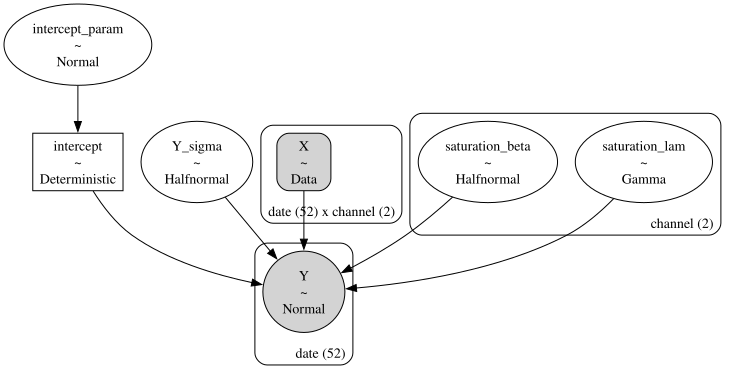

In [24]:
additive_gam.build_model(train)
pm.model_to_graphviz(additive_gam.model)

## 8. Look at the model before fitting

Prior predictive sampling draws parameters from their priors, then simulates `Y` using those parameters and our input `X`.
It does not learn from the observed `Y`.

In [25]:
prior = additive_gam.sample_prior_predictive(train, random_seed=42)

Sampling: [Y, Y_sigma, intercept_param, saturation_beta, saturation_lam]


Display the returned ArviZ object.
In this version of ArviZ, it is an `xarray.DataTree` with three groups:

- `prior`: sampled parameters and named terms, including `intercept`.
- `prior_predictive`: simulated responses `Y`.
- `observed_data`: the supplied observations, kept for comparison.

In [26]:
prior

<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:          (chain: 1, draw: 500, channel: 2)
│       Coordinates:
│         * chain            (chain) int64 8B 0
│         * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
│         * channel          (channel) <U6 48B 'tv' 'search'
│       Data variables:
│           saturation_beta  (chain, draw, channel) float64 8kB 2.509 1.213 ... 1.139
│           Y_sigma          (chain, draw) float64 4kB 0.2009 2.92 3.163 ... 0.656 1.833
│           saturation_lam   (chain, draw, channel) float64 8kB 3.41 2.714 ... 2.718
│           intercept        (chain, draw) float64 4kB -1.649 1.406 ... -0.4846 0.6711
│           intercept_param  (chain, draw) float64 4kB -1.649 1.406 ... -0.4846 0.6711
│       Attributes:
│           created_at:                 2026-10-15T09:35:51.342854+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 500, date: 52)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│         * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
│       Data variables:
│           Y        (chain, draw, date) float64 208kB 1.103 1.166 ... 1.04 0.986
│       Attributes:
│           created_at:                 2026-10-15T09:35:51.344553+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (date: 52)
        Coordinates:
          * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
        Data variables:
            Y        (date) float64 416B 1.65 2.026 1.172 1.954 ... 1.2 1.856 1.492
        Attributes:
            created_at:                 2026-10-15T09:35:51.345072+00:00
            creation_library:           ArviZ
            creation_library_version:   1.2.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

Open the `prior` group to see the samples and their dimensions.
The intercept has only `chain` and `draw`; the saturation parameters also have `channel`.

In [27]:
prior["prior"]

<xarray.DataTree 'prior'>
Group: /prior
    Dimensions:          (chain: 1, draw: 500, channel: 2)
    Coordinates:
      * chain            (chain) int64 8B 0
      * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
      * channel          (channel) <U6 48B 'tv' 'search'
    Data variables:
        saturation_beta  (chain, draw, channel) float64 8kB 2.509 1.213 ... 1.139
        Y_sigma          (chain, draw) float64 4kB 0.2009 2.92 3.163 ... 0.656 1.833
        saturation_lam   (chain, draw, channel) float64 8kB 3.41 2.714 ... 2.718
        intercept        (chain, draw) float64 4kB -1.649 1.406 ... -0.4846 0.6711
        intercept_param  (chain, draw) float64 4kB -1.649 1.406 ... -0.4846 0.6711
    Attributes:
        created_at:                 2026-10-15T09:35:51.342854+00:00
        creation_library:           ArviZ
        creation_library_version:   1.2.0
        creation_library_language:  Python
        inference_library:          pymc
        inference_library_version:  6.3.2
        sample_dims:                ['chain', 'draw']

Finally, compare the simulated and observed response distributions with ArviZ.
Pass `group="prior_predictive"` explicitly: these are predictions **before fitting**, not posterior predictions.

/Users/carlostrujillo/Documents/GitHub/_worktrees/pymc-marketing/agent-2963-experimental-mmm-notebook/.venv/lib/python3.13/site-packages/arviz_plots/plots/utils_ppc.py:68: UserWarning: This plot always uses the `observed_data` group.
Be cautious when using it for prior predictive checks.
  warn_if_prior_predictive(group)


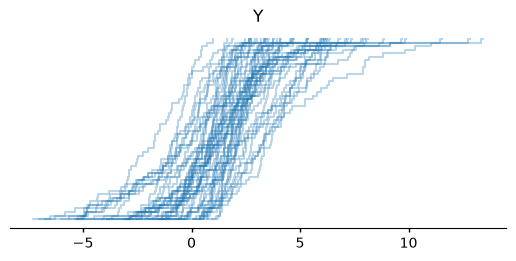

In [28]:
import arviz_plots as azp

azp.plot_ppc_dist(prior, group="prior_predictive", var_names=["Y"]);

The Normal model can generate negative responses, and the default noise prior is broad relative to our small synthetic values.
This check helps us judge whether the priors and likelihood suit the response scale; adding a term does not make those modeling choices automatically.
We have extended the response with `+` and checked its implications without changing how the data enter the model.

In [29]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Thu, 15 Oct 2026

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2

arviz_plots   : 1.2.0
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
xarray        : 2026.4.0

Watermark: 2.6.0

